# Assignment 8 — Movie Recommendation Systems

**Juan Luna Santibanez**  
**Miami Dade College | CAI2100C — Machine Learning Foundations**  
**Professor Beth Muturi**

## My two assigned tasks

1. **Task 1 — Content-Based Filtering:** I use IMDb movie metadata, TF-IDF and cosine similarity to recommend related films.
2. **Task 2 — Collaborative Filtering:** I study rating patterns from IMDb's available demographic cohorts, evaluate held-out group averages and explain the limitation of group-level data.

I use two IMDb CSV research samples in the project’s `data/` directory, following the same structure as my Assignment 7. If I open only this notebook in Google Colab, its loader retrieves the two CSVs from my public GitHub repository automatically. The notebook contains my methods, results, graphs and conclusions, **not thousands of pasted CSV records**.

**My data scope:** 3,000 authentic selected IMDb movies and 3,000 corresponding cohort rating rows, not the entire IMDb Extensive database. I keep the two tasks separate and do not claim personalized user recommendations from aggregated cohort averages.

[IMDb Extensive dataset](https://www.kaggle.com/datasets/stefanoleone992/imdb-extensive-dataset) · [Assignment 8 GitHub repository](https://github.com/SupaHumano/CAI2100C-Movie-Recommendation-Systems)


## 1. Load and inspect my IMDb dataset

Just as in Assignment 7, I keep the data files separate from the analysis. I first look for `IMDb movies.csv` and `IMDb ratings.csv` locally, including the project’s `data/` folder. If either file is absent, I retrieve that specific file from my GitHub repository. The supplied ZIP contains both CSVs, so it works without downloading anything after extraction.

The displayed output shows which source I used, the number of rows, and the fields needed for the two tasks.


In [1]:
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import linear_kernel

np.random.seed(42)
print('Python:', platform.python_version(), '| Pandas:', pd.__version__)

def recommend_by_content(frame, matrix, selected_title, k=10):
    found = np.flatnonzero(frame.title.astype(str).str.casefold().eq(selected_title.casefold()))
    if not len(found):
        raise ValueError('Title not found: '+selected_title)
    target = int(found[0])
    similarity = linear_kernel(matrix[target],matrix).ravel()
    indices = np.argsort(-similarity,kind='stable')
    indices = indices[indices!=target][:k]
    result = frame.iloc[indices][['title']].copy()
    result['cosine_similarity']=similarity[indices]
    return result.reset_index(drop=True)


Python: 3.13.5 | Pandas: 2.2.3


### IMDb research data

I use **3,000 selected movie records** from IMDb Extensive (at least 1,000 total votes, ordered by vote count) and their **3,000 corresponding demographic rating records**. They are real source records, but this selected sample overrepresents popular movies. The original data are stored as normal CSV files in `data/`, rather than being pasted into a code cell.


In [2]:
from pathlib import Path
from urllib.request import urlretrieve

# Same simple loading pattern as my Assignment 7: check local files first,
# then obtain missing CSV files from my own GitHub repository.
DATA_BASE = "https://raw.githubusercontent.com/SupaHumano/CAI2100C-Movie-Recommendation-Systems/main/data/"

def locate_csv(filename):
    cwd = Path.cwd()
    candidates = [
        cwd / "data" / filename,
        cwd.parent / "data" / filename,
        cwd / filename,
        cwd / "notebooks" / "data" / filename,
        Path("/content/data") / filename,
        Path("/content") / filename,
    ]
    if Path("/kaggle/input").is_dir():
        candidates += list(Path("/kaggle/input").glob("**/" + filename))
    source = next((p for p in candidates if p.is_file()), None)
    if source is not None:
        return source
    target = cwd / "data" / filename
    target.parent.mkdir(parents=True, exist_ok=True)
    urlretrieve(DATA_BASE + filename.replace(" ", "%20"), target)
    return target

movies_path = locate_csv("IMDb movies.csv")
ratings_path = locate_csv("IMDb ratings.csv")
imdb_movies_raw = pd.read_csv(movies_path, low_memory=False)
imdb_ratings_raw = pd.read_csv(ratings_path, low_memory=False)
assert len(imdb_movies_raw) == 3000 and len(imdb_ratings_raw) == 3000
assert imdb_movies_raw.imdb_title_id.is_unique
assert imdb_ratings_raw.imdb_title_id.is_unique
print("IMDb movies:", len(imdb_movies_raw), "| source:", movies_path)
print("IMDb rating records:", len(imdb_ratings_raw), "| source:", ratings_path)
display(imdb_movies_raw[["title", "genre", "votes", "avg_vote"]].head())


IMDb movies: 3000 | source: /tmp/tmpgmp9bq8f/assignment8/data/IMDb movies.csv
IMDb rating records: 3000 | source: /tmp/tmpgmp9bq8f/assignment8/data/IMDb ratings.csv


,title,genre,votes,avg_vote
0,Le ali della libertà,Drama,2278845,9.3
1,Il cavaliere oscuro,"Action, Crime, Drama",2241615,9.0
2,Inception,"Action, Adventure, Sci-Fi",2002816,8.8
3,Fight Club,Drama,1807440,8.8
4,Pulp Fiction,"Crime, Drama",1780147,8.9


## Task 1 — Content-Based Filtering

I represent each movie using its **genre, director, actors and description**. TF-IDF converts the text into numerical word features; I compare those feature vectors with **cosine similarity** and recommend other movies with related text. I exclude the original query title.

A high similarity value describes metadata resemblance. It does **not** guarantee that a person will like both films.


In [3]:
COHORTS = {
 'Women 18–29': ('females_18age_avg_vote', 'females_18age_votes'),
 'Women 30–44': ('females_30age_avg_vote', 'females_30age_votes'),
 'Women 45+': ('females_45age_avg_vote', 'females_45age_votes'),
 'Men 18–29': ('males_18age_avg_vote', 'males_18age_votes'),
 'Men 30–44': ('males_30age_avg_vote', 'males_30age_votes'),
 'Men 45+': ('males_45age_avg_vote', 'males_45age_votes')}
cohort_cols = [c for pair in COHORTS.values() for c in pair]
assert {'imdb_title_id','title','genre','description','director','actors','votes','avg_vote'}.issubset(imdb_movies_raw.columns)
assert {'imdb_title_id', *cohort_cols}.issubset(imdb_ratings_raw.columns)

imdb_movies=imdb_movies_raw.copy()
imdb_movies['votes']=pd.to_numeric(imdb_movies['votes'],errors='coerce').fillna(0)
imdb_movies['avg_vote']=pd.to_numeric(imdb_movies['avg_vote'],errors='coerce')
imdb_movies=imdb_movies[imdb_movies.votes.ge(1000)&imdb_movies.title.notna()&imdb_movies.imdb_title_id.notna()].copy()
imdb_movies=imdb_movies.sort_values(['votes','imdb_title_id'],ascending=[False,True]).drop_duplicates('imdb_title_id').head(3000)
for col in ['title','genre','description','director','actors']:
    imdb_movies[col]=imdb_movies[col].fillna('').astype(str)
# Ignore duplicated keys in the right-hand table, not the movie rows themselves.
imdb_ratings_unique=imdb_ratings_raw[['imdb_title_id']+cohort_cols].drop_duplicates('imdb_title_id')
imdb_movies=imdb_movies.merge(imdb_ratings_unique,on='imdb_title_id',how='left',validate='one_to_one').reset_index(drop=True)
assert len(imdb_movies)>=5
print('IMDb titles in reproducible analysis subset:',len(imdb_movies))
display(imdb_movies[['title','genre','votes','avg_vote']].head())


IMDb titles in reproducible analysis subset: 3000


,title,genre,votes,avg_vote
0,Le ali della libertà,Drama,2278845,9.3
1,Il cavaliere oscuro,"Action, Crime, Drama",2241615,9.0
2,Inception,"Action, Adventure, Sci-Fi",2002816,8.8
3,Fight Club,Drama,1807440,8.8
4,Pulp Fiction,"Crime, Drama",1780147,8.9


Selected IMDb title: Le ali della libertà


,title,cosine_similarity
0,Glory - Uomini di gloria,0.1526
1,World Trade Center,0.1384
2,Aliens - Scontro finale,0.1248
3,Hurricane - Il grido dell'innocenza,0.1225
4,Sin City,0.1222
5,Americani,0.1200
6,Wanted - Scegli il tuo destino,0.1195
7,SpongeBob - Il film,0.1188
8,Highwaymen - L'ultima imboscata,0.1166
9,Nome in codice: Broken Arrow,0.1139


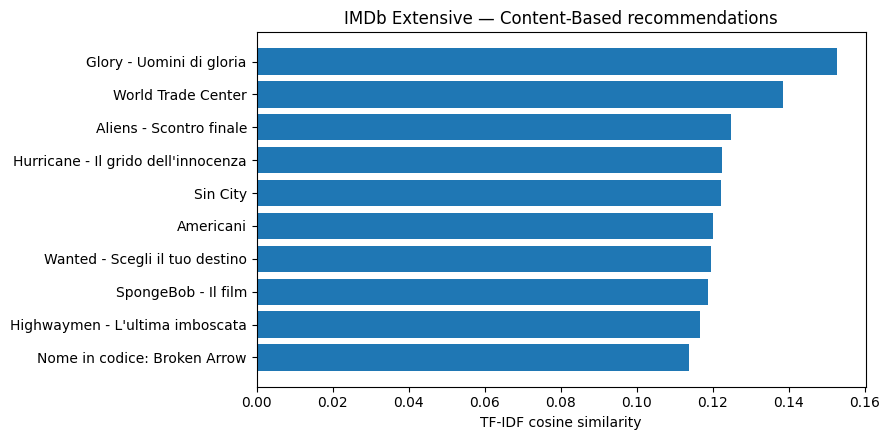

In [4]:
imdb_text=(imdb_movies.genre.str.replace(',',' ',regex=False)+' '+
           imdb_movies.director.str.replace(',',' ',regex=False)+' '+
           imdb_movies.actors.str.replace(',',' ',regex=False)+' '+imdb_movies.description)
imdb_vectorizer=TfidfVectorizer(stop_words='english',ngram_range=(1,2),max_features=6000)
imdb_features=imdb_vectorizer.fit_transform(imdb_text)
imdb_title=str(imdb_movies.iloc[0].title)
imdb_content=recommend_by_content(imdb_movies,imdb_features,imdb_title,k=10)
print('Selected IMDb title:',imdb_title)
display(imdb_content.round(4))
assert len(imdb_content)==10
fig,ax=plt.subplots(figsize=(9,4.5));table=imdb_content.iloc[::-1]
ax.barh(table.title.str.slice(0,38),table.cosine_similarity)
ax.set(title='IMDb Extensive — Content-Based recommendations',xlabel='TF-IDF cosine similarity')
fig.tight_layout();plt.show()


## Task 2 — Collaborative Filtering approximation

The IMDb Extensive ratings file contains **aggregated audience statistics**, not `userId`–`movieId`–`rating` interactions. I therefore compare six demographic audience groups instead of claiming personalized recommendations.

I represent their film-average ratings in a group-by-movie matrix, require at least **30 votes** for a group/movie observation, and calculate **Pearson correlations** for groups with enough common movies. I estimate a group's missing average rating from positively correlated groups.

For evaluation, I hide approximately **15% of eligible observed group averages**, compute predictions from training observations only, and report **MAE**, **RMSE** and a simple training-group-mean baseline. The scores describe group-average errors on IMDb's 1–10 scale, not individuals' preferences.


IMDb matrix dimensions (groups × movies): (6, 3000)


,Women 18–29,Women 30–44,Women 45+,Men 18–29,Men 30–44,Men 45+
Women 18–29,1.000,0.978,0.915,0.940,0.923,0.894
Women 30–44,0.978,1.000,0.952,0.937,0.948,0.936
Women 45+,0.915,0.952,1.000,0.870,0.893,0.950
Men 18–29,0.940,0.937,0.870,1.000,0.984,0.935
Men 30–44,0.923,0.948,0.893,0.984,1.000,0.964
Men 45+,0.894,0.936,0.950,0.935,0.964,1.000


,Value
Held-out group means,2700.000000
MAE,0.183546
RMSE,0.247744
Training-group-mean baseline MAE,0.704668


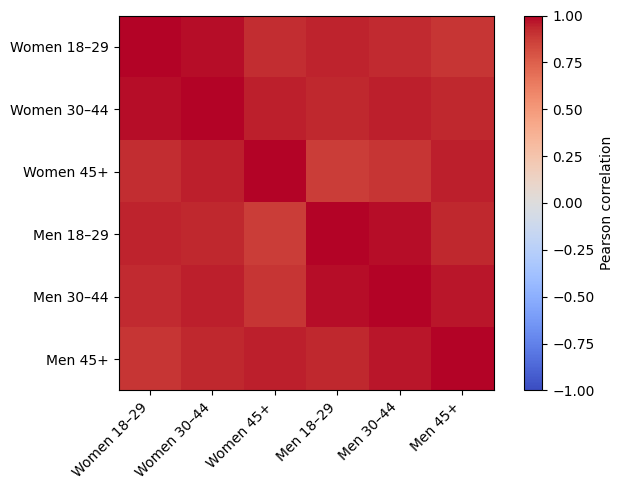

In [5]:
def make_cohort_matrix(frame,min_votes=30):
    rows=[]
    for mean_col,votes_col in COHORTS.values():
        mean=pd.to_numeric(frame[mean_col],errors='coerce')
        nvotes=pd.to_numeric(frame[votes_col],errors='coerce').fillna(0)
        rows.append(mean.where(mean.between(1,10)&nvotes.ge(min_votes)).to_numpy(float))
    return pd.DataFrame(rows,index=list(COHORTS),columns=frame.imdb_title_id.tolist())

def group_similarity(groups,min_overlap=15):
    x=groups.to_numpy(float);n=x.shape[0];sim=np.eye(n)
    for i in range(n):
        for j in range(i+1,n):
            valid=np.isfinite(x[i])&np.isfinite(x[j])
            if valid.sum()>=min_overlap and np.std(x[i,valid])>1e-12 and np.std(x[j,valid])>1e-12:
                s=np.corrcoef(x[i,valid],x[j,valid])[0,1]
                sim[i,j]=sim[j,i]=float(np.clip(s,-1,1)) if np.isfinite(s) else 0.0
            else:sim[i,j]=sim[j,i]=0.0
    return pd.DataFrame(sim,index=groups.index,columns=groups.index)

def predict_group_average(groups,similarity,row,col):
    x=groups.to_numpy(float)
    group_av=np.nanmean(x,axis=1)
    global_mean=float(np.nanmean(x))
    base=float(group_av[row]) if np.isfinite(group_av[row]) else global_mean
    w=similarity.iloc[row].to_numpy(float).copy();w[row]=0
    good=(w>0)&np.isfinite(x[:,col])&np.isfinite(group_av)
    if not good.any():return float(np.clip(base,1,10))
    result=base+np.dot(w[good],x[good,col]-group_av[good])/w[good].sum()
    return float(np.clip(result,1,10))

def evaluate_groups(groups,seed=42,fraction=0.15):
    x=groups.to_numpy(float)
    pairs=np.argwhere(np.isfinite(x))
    if len(pairs)<60:raise ValueError('Need at least 60 observed demographic averages for validation')
    rng=np.random.default_rng(seed);rng.shuffle(pairs)
    train=groups.copy()
    withheld=[];max_holdout=max(1,round(len(pairs)*fraction))
    for row,col in pairs:
        if len(withheld)>=max_holdout:break
        if train.iloc[row].notna().sum()<=15 or train.iloc[:,col].notna().sum()<=2:continue
        withheld.append((int(row),int(col),float(groups.iloc[row,col])))
        train.iloc[row,col]=np.nan
    if not withheld:raise ValueError('Unable to select any evaluable holdout')
    sims=group_similarity(train)
    y_true=np.array([value for _,_,value in withheld])
    y_pred=np.array([predict_group_average(train,sims,row,col) for row,col,_ in withheld])
    group_means=np.nanmean(train.to_numpy(float),axis=1)
    baseline=np.array([group_means[row] for row,_,_ in withheld])
    diff=y_pred-y_true
    return {'Held-out group means':len(y_true),'MAE':float(np.mean(abs(diff))),
            'RMSE':float(np.sqrt(np.mean(diff**2))),
            'Training-group-mean baseline MAE':float(np.mean(abs(baseline-y_true)))},train

imdb_groups=make_cohort_matrix(imdb_movies)
imdb_sim=group_similarity(imdb_groups)
print('IMDb matrix dimensions (groups × movies):',imdb_groups.shape)
display(imdb_sim.round(3))
imdb_scores,imdb_train_groups=evaluate_groups(imdb_groups)
display(pd.DataFrame([imdb_scores]).T.rename(columns={0:'Value'}))
assert np.isfinite(imdb_scores['MAE'])
fig,ax=plt.subplots(figsize=(7,5))
heat=ax.imshow(imdb_sim.to_numpy(),vmin=-1,vmax=1,cmap='coolwarm')
ax.set_xticks(range(6),imdb_sim.columns,rotation=45,ha='right')
ax.set_yticks(range(6),imdb_sim.index)
fig.colorbar(heat,ax=ax,label='Pearson correlation');fig.tight_layout();plt.show()


In [6]:
# Example estimates for a named cohort. If no cells are missing, demonstrate estimates for sufficiently observed movies.
chosen_group='Women 18–29'; row=list(imdb_groups.index).index(chosen_group)
available=np.flatnonzero(imdb_groups.iloc[row].isna().to_numpy() & (imdb_groups.notna().sum(axis=0).to_numpy()>=2))
reason='Missing group-average estimates'
if not len(available):
    available=np.flatnonzero(imdb_groups.notna().sum(axis=0).to_numpy()>=3)
    reason='Illustrative group-average estimates for observed movie IDs (not unobserved personal preferences)'
if not len(available):raise ValueError('Not enough IMDb group-mean observations for ranking')
est=np.array([predict_group_average(imdb_groups,imdb_sim,row,int(j)) for j in available])
order=np.argsort(-est)[:10]
keys=imdb_groups.columns[available[order]]
imdb_group_top=imdb_movies.set_index('imdb_title_id').loc[keys,['title','genre','avg_vote']].copy()
imdb_group_top['estimated_group_average']=est[order]
print('IMDb group:',chosen_group,'|',reason)
display(imdb_group_top.reset_index())


IMDb group: Women 18–29 | Illustrative group-average estimates for observed movie IDs (not unobserved personal preferences)


,index,title,genre,avg_vote,estimated_group_average
0,tt0111161,Le ali della libertà,Drama,9.3,9.369949
1,tt0068646,Il padrino,"Crime, Drama",9.2,9.247216
2,tt0071562,Il padrino - Parte II,"Crime, Drama",9.0,9.047216
3,tt0108052,Schindler's List,"Biography, Drama, History",8.9,9.030874
4,tt0050083,La parola ai giurati,"Crime, Drama",8.9,8.990699
5,tt0167260,Il Signore degli Anelli - Il ritorno del re,"Action, Adventure, Drama",8.9,8.971838
6,tt0120737,Il Signore degli Anelli - La compagnia dell'An...,"Action, Adventure, Drama",8.8,8.930058
7,tt0468569,Il cavaliere oscuro,"Action, Crime, Drama",9.0,8.873832
8,tt0110912,Pulp Fiction,"Crime, Drama",8.9,8.867750
9,tt0109830,Forrest Gump,"Drama, Romance",8.8,8.831569


## My results and interpretation

I compare the two **required IMDb methods**, not different rating scales or unrelated datasets. Content-Based Filtering yields a ranked list of similar movies, whereas the cohort-correlation approach produces estimated **group-level averages**. These methods answer different questions, so I do not compare their cosine similarity values with MAE/RMSE as if they were identical measurements.


In [7]:
summary = pd.DataFrame([
 {'Task':'1 — Content-Based', 'Data':'Movie descriptions and metadata', 'Result':f'{len(imdb_content)} recommended films', 'Measurement':'TF-IDF cosine similarity'},
 {'Task':'2 — Cohort rating patterns', 'Data':'Six demographic rating groups', 'Result':f'{imdb_scores["Held-out group means"]} held-out group means', 'Measurement':f'MAE {imdb_scores["MAE"]:.4f}; RMSE {imdb_scores["RMSE"]:.4f}; baseline MAE {imdb_scores["Training-group-mean baseline MAE"]:.4f}'}
])
display(summary)
print('PASS — Both assigned IMDb recommendation methods completed from embedded real source records.')


,Task,Data,Result,Measurement
0,1 — Content-Based,Movie descriptions and metadata,10 recommended films,TF-IDF cosine similarity
1,2 — Cohort rating patterns,Six demographic rating groups,2700 held-out group means,MAE 0.1835; RMSE 0.2477; baseline MAE 0.7047


PASS — Both assigned IMDb recommendation methods completed from embedded real source records.


## My conclusion

I found that the **Content-Based** method recommends movies based on information describing their content. My second approach studies IMDb's **demographic rating patterns** using correlations between cohort averages; because it does not contain individual user histories, it cannot predict a particular viewer's preferences in the way that user-based collaborative filtering or SVD can.

**Limitations:** I used 3,000 selected IMDb titles rather than the entire original collection; popular titles are overrepresented. Cohort averages are aggregated statistics, not personal ratings. I reported held-out evaluation with a training-only baseline and documented the scope of each result.

**Sources:** [Stefano Leone, IMDb Extensive](https://www.kaggle.com/datasets/stefanoleone992/imdb-extensive-dataset); Professor Beth Muturi's Assignment 8 notebook; [Rounak Banik, Movie Recommender Systems](https://www.kaggle.com/code/rounakbanik/movie-recommender-systems); [scikit-learn TF-IDF](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html).
